In [1]:
__author__ = "Pablo González Ferro"

# Proyecto AA. EDA del conjunto `proy_diabetes_dev.csv`

En este notebook hago el análisis exploratorio de los datos de la encuesta de salud del consorcio. Sobre estos datos hay que trabajar tres líneas: **clusterización** (perfiles de paciente), **clasificación** (`diabetes`) y **regresión** (`dias_salud_fisica_mala`, de 0 a 30).

Las preguntas que quiero responder son:

- ¿Qué problemas de calidad tienen los datos y cómo se tratan?
- ¿Qué variables se relacionan más con la diabetes y con los días de mala salud física?
- ¿Cómo son las dos variables objetivo y qué implica eso para elegir modelo y métrica?
- ¿Hay alguna estructura en los pacientes que sirva para sacar perfiles?

Primero reviso la estructura y la calidad de los datos (apuntando cada problema en un registro de incidencias), y después analizo las distribuciones, las relaciones, los nulos, los atípicos y las variables objetivo.

## 0. Preparación

In [2]:
# Manejo de dataframes
import pandas as pd

# Operaciones numéricas
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de Scikit-Learn para la exploración orientada al clustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Quito los avisos de versiones para que no ensucien la salida
import warnings
warnings.filterwarnings("ignore")

# Que se vean todas las columnas al mostrar un dataframe
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Estilo de los gráficos
sns.set_theme(style="whitegrid")

# Ruta al CSV del proyecto (está en la misma carpeta que el notebook)
RUTA_DATOS = "proy_diabetes_dev.csv"

# Semilla para que lo que tenga aleatoriedad (muestras y PCA) salga siempre igual
SEMILLA = 42

### Catálogo de incidencias

Cada problema que encuentre lo clasifico con una de estas etiquetas. Las cuatro últimas las añado yo porque este dataset tiene problemas que no encajan en las demás.

| Etiqueta | Significado |
|---|---|
| `nulo_centinela` | Ausencia de dato codificada como un valor aparentemente válido |
| `duplicado_exacto` | Filas repetidas en su totalidad |
| `duplicado_parcial` | Filas que describen el mismo hecho pero difieren en algún campo |
| `unidad_inconsistente` | Una misma columna expresada en más de una unidad |
| `formato_fecha_inconsistente` | Fechas con más de un formato |
| `categoria_inconsistente` | Una misma categoría escrita de varias formas |
| `atipico_imposible` | Valores físicamente imposibles |
| `fuga_de_informacion` | Variables no disponibles en el momento de predecir |
| `codificacion_corrupta` | Texto degradado por una mala codificación |
| `fila_desplazada` | Filas con los valores corridos de columna |
| `dato_personal` | Columna con datos personales ofuscados |
| `columna_sin_valor_predictivo` | Columna de gestión o identificador que no describe al paciente |
| `valor_ausente` | Dato que falta (celda vacía) |
| `atipico_extremo` | Valor muy alejado del resto pero posible |

In [3]:
# Etiquetas del catálogo de incidencias
CATALOGO = [
    "nulo_centinela",
    "duplicado_exacto",
    "duplicado_parcial",
    "unidad_inconsistente",
    "formato_fecha_inconsistente",
    "categoria_inconsistente",
    "atipico_imposible",
    "fuga_de_informacion",
    "codificacion_corrupta",
    "fila_desplazada",
    "dato_personal",
    "columna_sin_valor_predictivo",
    "valor_ausente",
    "atipico_extremo",
]

COL_FILA = "(fila)"

# Aquí se va acumulando la auditoría. Se vuelca a `incidencias.csv` al final del notebook.
INCIDENCIAS = []


def registra(columna, tipo_incidencia, n_filas_afectadas, accion):
    """Anota una incidencia en el registro de la auditoría.

    Valida la etiqueta contra el catálogo, así una errata en el nombre del tipo salta
    al momento en vez de colarse en el registro.
    """
    if tipo_incidencia not in CATALOGO:
        raise ValueError(
            f"«{tipo_incidencia}» no está en el catálogo. Use uno de: {CATALOGO}"
        )
    INCIDENCIAS.append(
        {
            "columna": columna,
            "tipo_incidencia": tipo_incidencia,
            "n_filas_afectadas": int(n_filas_afectadas),
            "accion": accion,
        }
    )
    print(f"Registrada: {columna} / {tipo_incidencia} ({n_filas_afectadas} filas)")

## 1. Estructura de los datos

### 1.1 Carga e inspección inicial

Cargo todo como texto y sin interpretar los nulos, para ver los datos exactamente como vienen. `crudo` se queda intacto durante todo el notebook.

In [4]:
# dtype=str y keep_default_na=False: pandas no convierte nada, todo llega tal cual como texto
crudo = pd.read_csv(RUTA_DATOS, dtype=str, keep_default_na=False)

# Dimensiones del conjunto de datos
print("Forma:", crudo.shape)
crudo.head()

Forma: (12750, 29)


,id_paciente_proy,dni,nombre,apellidos,direccion,telefono,email,num_historia_clinica,presion_alta,colesterol_alto,chequeo_colesterol_5a,imc,fumador,ictus,enfermedad_cardiaca,actividad_fisica,consume_fruta,consume_verdura,consumo_alcohol_alto,salud_general,dias_salud_mental_mala,dias_salud_fisica_mala,dificultad_caminar,sexo,grupo_edad,nivel_educativo,nivel_ingresos,diabetes,usuario_alta_datos
0,90,9002b707403a13310b63559f1424a2a3,55f15684574c8895c4234fb7987d23cb,cde3522f31388e7cfe8663f173e07bc0,5a0d0afae7c4f2b727332e30663222ee,16a767cbb4bbeb01d995a44e320ac087,9ba86cc234d2bc2067fec10ff049a7aa,da2d03b68a2745843ee1060fc98a346c,si,si,si,,no,no,no,si,si,si,no,,,0,no,hombre,55-59,secundaria,,no,admin
1,2443,162319c0551225e9fe2c5da7b6d52e71,30c9a0e33312b54775ee3fc1d34483d7,86996ec928b462ee8f0343ffbe0f82b1,c16b76aaa2d4abca01b67816003c67a2,7176ee8d6dae058edcb75528c0d74951,84077d4793dc2403eb934b9ad8490187,97b18957d6589adf7a7fd119a8959ef8,si,si,si,41.0,NO,no,no,NO,SI,si,no,buena,0.0,0,SI,mujer,80+,secundaria,10-15k,si,us_admision_1
2,11061,e7fee47d66a627a2bd11e1abcb6fc71d,fa9b67a5f04ab381a655ce11f71ede16,1de54ad005a1c2e875664eb4e3e3b0e3,159882b4d4946b7ae0cb163e731af530,ffb6bb2a2189224fd204a4e7015ddac1,674f85328d69d9c64b29aa1f05fe42d1,2e2922cdd75430e622f1540f5614679f,si,si,si,30.0,no,no,no,si,no,si,no,muy buena,0.0,0,no,hombre,60-64,secundaria,35-50k,si,us_admision_1
3,4777,ed14f2ce7d014c27d4f65190e7a9f2bd,1a25cd782eafac0e7613b53daab84118,8f6a795e173f85e9eef5b15d2ca9d0ce,e6b9d22501402431c452cdc8bdfcfbc0,ab92997db67891fd459f7f655cf8154a,8f7a38fcc02a52059f111b68702bf21b,ba5bbe61c14e46778133748b770d873b,si,si,si,36.0,si,no,no,no,si,si,no,buena,0.0,2,si,mujer,60-64,titulado superior,>75k,si,us_admision_2
4,14534,7b15ec3e056f5f2f6edaa83c77201f00,b712489fdcf4c8946982dc81e192f344,c068e6fc1dd7f60ea956fa46d18fbc3c,30fc1cb6ccc6e5f6d9dc154d1df9c527,6b12d7e59d47d9bd0a7003ab8b29eb74,75c31956bcd1af3079a6bb6f4970ac8d,9c5187719c6a3b5c27e1c94ff4d515f6,no,si,si,30.0,no,no,no,si,no,no,no,muy buena,5.0,30,si,hombre,50-54,secundaria,50-75k,no,us_admision_1


In [5]:
# Resumen por columna: nº de valores distintos, nº de celdas vacías y unos cuantos ejemplos.
# Con esto de un vistazo veo qué columnas son raras.
resumen = pd.DataFrame({
    "n_unicos": crudo.nunique(),
    "celdas_vacias": (crudo == "").sum(),
    "ejemplos": [crudo[c].unique()[:6].tolist() for c in crudo.columns],
})
resumen

,n_unicos,celdas_vacias,ejemplos
id_paciente_proy,12750,0,"[90, 2443, 11061, 4777, 14534, 5582]"
dni,12750,0,"[9002b707403a13310b63559f1424a2a3, 162319c0551..."
nombre,12750,0,"[55f15684574c8895c4234fb7987d23cb, 30c9a0e3331..."
apellidos,12750,0,"[cde3522f31388e7cfe8663f173e07bc0, 86996ec928b..."
direccion,12750,0,"[5a0d0afae7c4f2b727332e30663222ee, c16b76aaa2d..."
telefono,12750,0,"[16a767cbb4bbeb01d995a44e320ac087, 7176ee8d6da..."
email,12750,0,"[9ba86cc234d2bc2067fec10ff049a7aa, 84077d4793d..."
num_historia_clinica,12750,0,"[da2d03b68a2745843ee1060fc98a346c, 97b18957d65..."
presion_alta,2,0,"[si, no]"
colesterol_alto,2,0,"[si, no]"


Hay **12.750 registros y 29 columnas**, que se dividen en tres grupos:

- **Identificador y datos personales ofuscados** (`id_paciente_proy`, `dni`, `nombre`...).
- **Una columna de gestión**: `usuario_alta_datos`, quién metió el registro.
- **Variables de la encuesta**: binarias (si/no), el IMC, dos conteos de días y cuatro ordinales.

Además, algunas binarias como `fumador` tienen 9 valores distintos en vez de 2, así que vienen escritas de varias formas.

### 1.2 Auditoría de calidad

Construyo `limpio` a partir de `crudo` y voy corrigiendo y registrando cada problema.

In [6]:
# A partir de aquí todas las correcciones se hacen sobre `limpio`, `crudo` no se toca
limpio = crudo.copy()

#### 1.2.1 Datos personales ofuscados

Compruebo que son cadenas aleatorias, es decir, valores únicos con forma de hash.

In [7]:
# Columnas con datos personales según el enunciado
COLS_PII = ["dni", "nombre", "apellidos", "direccion", "telefono", "email", "num_historia_clinica"]

# Para cada una miro si todos los valores son únicos, qué longitud tienen y si son hexadecimales (tipo hash MD5)
pd.DataFrame({
    "n_unicos": crudo[COLS_PII].nunique(),
    "todos_unicos": crudo[COLS_PII].nunique() == len(crudo),
    "longitud_cadena": [crudo[c].str.len().unique().tolist() for c in COLS_PII],
    "es_hex": [crudo[c].str.fullmatch(r"[0-9a-f]+").all() for c in COLS_PII],
})

,n_unicos,todos_unicos,longitud_cadena,es_hex
dni,12750,True,[32],True
nombre,12750,True,[32],True
apellidos,12750,True,[32],True
direccion,12750,True,[32],True
telefono,12750,True,[32],True
email,12750,True,[32],True
num_historia_clinica,12750,True,[32],True


Las siete columnas son hashes de 32 caracteres, distintos en cada fila. No describen nada del paciente y además son datos protegidos, así que las elimino.

In [8]:
# Elimino las siete columnas y lo dejo apuntado en el registro, una entrada por columna
limpio = limpio.drop(columns=COLS_PII)
for c in COLS_PII:
    registra(
        columna=c,
        tipo_incidencia="dato_personal",
        n_filas_afectadas=len(crudo),
        accion="Columna eliminada: cadena aleatoria sin valor para el modelado.",
    )

Registrada: dni / dato_personal (12750 filas)
Registrada: nombre / dato_personal (12750 filas)
Registrada: apellidos / dato_personal (12750 filas)
Registrada: direccion / dato_personal (12750 filas)
Registrada: telefono / dato_personal (12750 filas)
Registrada: email / dato_personal (12750 filas)
Registrada: num_historia_clinica / dato_personal (12750 filas)


#### 1.2.2 Identificador y columna de gestión

Compruebo que el id no "chiva" quién es diabético (por ejemplo, si el remuestreo se hubiera hecho por bloques de id) y que el usuario que mete los datos no influye en los objetivos.

In [9]:
# El id tiene que ser único para servir de índice
id_num = pd.to_numeric(crudo["id_paciente_proy"])
print("id único:", id_num.is_unique)

# Comparo los estadísticos descriptivos del id entre diabéticos y no diabéticos.
# Si el remuestreo se hubiera hecho por bloques de id, aquí se verían rangos distintos
display(id_num.groupby(crudo["diabetes"]).describe().round(1))

# Para cada usuario: cuántos registros mete, qué % son diabéticos y la media de días de mala salud física
pd.DataFrame({
    "n_registros": crudo["usuario_alta_datos"].value_counts(),
    "%_diabetes": (crudo["diabetes"] == "si").groupby(crudo["usuario_alta_datos"]).mean() * 100,
    "media_dias_fisica_mala": pd.to_numeric(crudo["dias_salud_fisica_mala"]).groupby(crudo["usuario_alta_datos"]).mean(),
}).round(2)

id único: True


,count,mean,std,min,25%,50%,75%,max
diabetes,,,,,,,,
no,8512.0,7479.2,4333.8,1.0,3726.0,7469.0,11240.2,15000.0
si,4238.0,7478.4,4334.7,2.0,3741.5,7505.5,11192.8,14997.0


,n_registros,%_diabetes,media_dias_fisica_mala
usuario_alta_datos,,,
admin,3166,34.37,5.08
enfermeria.turno_a,3154,32.82,5.00
us_admision_1,3233,33.00,5.00
us_admision_2,3197,32.78,4.83


El id es único y su distribución es prácticamente igual en diabéticos y no diabéticos, así que no hay fuga de información. Los cuatro usuarios meten un número parecido de registros, con casi la misma proporción de diabéticos (entre el 32,8 % y el 34,4 %) y la misma media de días de mala salud.

Por tanto, el id lo uso solo como índice y `usuario_alta_datos` la elimino.

In [10]:
# El id pasa a ser el índice y deja de ser una columna más
limpio["id_paciente_proy"] = pd.to_numeric(limpio["id_paciente_proy"])
limpio = limpio.set_index("id_paciente_proy")
registra(
    columna="id_paciente_proy",
    tipo_incidencia="columna_sin_valor_predictivo",
    n_filas_afectadas=len(crudo),
    accion="Usado como índice, fuera de las variables de entrada.",
)

# La columna de gestión se elimina
limpio = limpio.drop(columns=["usuario_alta_datos"])
registra(
    columna="usuario_alta_datos",
    tipo_incidencia="columna_sin_valor_predictivo",
    n_filas_afectadas=len(crudo),
    accion="Columna eliminada: columna de gestión interna sin relación con los objetivos.",
)

Registrada: id_paciente_proy / columna_sin_valor_predictivo (12750 filas)
Registrada: usuario_alta_datos / columna_sin_valor_predictivo (12750 filas)


#### 1.2.3 Binarias escritas de varias formas

In [11]:
# Todas las columnas que deberían ser si/no
COLS_BIN = ["presion_alta", "colesterol_alto", "chequeo_colesterol_5a", "fumador", "ictus",
            "enfermedad_cardiaca", "actividad_fisica", "consume_fruta", "consume_verdura",
            "consumo_alcohol_alto", "dificultad_caminar", "diabetes"]

# Muestro solo las que tienen algo más que "si", "no" o vacío
for c in COLS_BIN:
    valores = set(crudo[c].unique()) - {"si", "no", ""}
    if valores:
        print(f"{c}: {crudo[c].value_counts().to_dict()}")

fumador: {'no': 4895, 'si': 4279, 'False': 831, 'True': 678, '0.0': 501, '1.0': 428, 'NO': 403, '': 376, 'SI': 359}
actividad_fisica: {'si': 6665, 'no': 2509, 'True': 1100, '1.0': 667, 'SI': 543, 'False': 409, '': 376, '0.0': 262, 'NO': 219}
consume_fruta: {'si': 5669, 'no': 3505, 'True': 934, 'False': 575, '1.0': 563, 'SI': 440, '': 376, '0.0': 366, 'NO': 322}
dificultad_caminar: {'no': 7125, 'si': 2049, 'False': 1213, '0.0': 724, 'NO': 602, '': 376, 'True': 296, '1.0': 205, 'SI': 160}


In [12]:
# ¿Las codificaciones raras vienen de un usuario concreto? Lo miro con fumador
display(pd.crosstab(crudo["fumador"].replace("", "(vacío)"), crudo["usuario_alta_datos"]))

# ¿Son siempre las mismas filas las que vienen mal escritas en las cuatro columnas?
COLS_BIN_MAL = ["fumador", "actividad_fisica", "consume_fruta", "dificultad_caminar"]
mal_escritas = ~crudo[COLS_BIN_MAL].isin(["si", "no", ""])
print("Filas con alguna columna mal escrita:", mal_escritas.any(axis=1).sum())
print("Filas con las cuatro columnas mal escritas:", mal_escritas.all(axis=1).sum())

usuario_alta_datos,admin,enfermeria.turno_a,us_admision_1,us_admision_2
fumador,,,,
(vacío),102,104,80,90
0.0,119,120,134,128
1.0,93,126,102,107
False,226,196,207,202
NO,96,101,103,103
SI,81,86,85,107
True,182,164,172,160
no,1208,1213,1255,1219
si,1059,1044,1095,1081


Filas con alguna columna mal escrita: 3200
Filas con las cuatro columnas mal escritas: 3200


Cuatro columnas (`fumador`, `actividad_fisica`, `consume_fruta` y `dificultad_caminar`) mezclan `si/no`, `SI/NO`, `True/False` y `1.0/0.0`. Son siempre las mismas 3.200 filas y están repartidas entre los cuatro usuarios, así que parece un fallo al exportar un bloque de registros.

Si no se arregla, el modelo trataría `si` y `SI` como cosas distintas. Como el significado está claro, paso todas las variantes a 1/0 (y `sexo` a hombre = 1, mujer = 0).

In [13]:
# Diccionario para traducir todas las variantes a 0/1 (la comparación se hace en minúsculas)
MAPA_BIN = {"si": 1, "true": 1, "1.0": 1, "1": 1, "no": 0, "false": 0, "0.0": 0, "0": 0}

for c in COLS_BIN:
    # Cuento las filas que no estaban escritas como "si"/"no" antes de corregir
    n_incons = int((~crudo[c].isin(["si", "no", ""])).sum())
    # Las celdas vacías pasan a NaN y el resto se traduce con el diccionario
    limpio[c] = limpio[c].replace("", np.nan).str.strip().str.lower().map(MAPA_BIN).astype("Int64")
    if n_incons:
        registra(
            columna=c,
            tipo_incidencia="categoria_inconsistente",
            n_filas_afectadas=n_incons,
            accion="Unificadas las variantes si/SI/True/1.0 y no/NO/False/0.0 a 1/0.",
        )

# sexo: hombre = 1, mujer = 0
limpio["sexo"] = limpio["sexo"].map({"hombre": 1, "mujer": 0}).astype("Int64")

# Compruebo que ninguna binaria tiene más de dos valores tras corregir
print(limpio[COLS_BIN + ["sexo"]].nunique().to_dict())

Registrada: fumador / categoria_inconsistente (3200 filas)


Registrada: actividad_fisica / categoria_inconsistente (3200 filas)
Registrada: consume_fruta / categoria_inconsistente (3200 filas)


Registrada: dificultad_caminar / categoria_inconsistente (3200 filas)
{'presion_alta': 2, 'colesterol_alto': 2, 'chequeo_colesterol_5a': 2, 'fumador': 2, 'ictus': 2, 'enfermedad_cardiaca': 2, 'actividad_fisica': 2, 'consume_fruta': 2, 'consume_verdura': 2, 'consumo_alcohol_alto': 2, 'dificultad_caminar': 2, 'diabetes': 2, 'sexo': 2}


#### 1.2.4 Valores ausentes

Busco los nulos, tanto celdas vacías como textos típicos de nulo (`NA`, `null`, `?`...).

In [14]:
# Textos que se suelen usar para marcar un nulo
TEXTOS_NULO = {"na", "nan", "null", "none", "?", "-", "n/a", "desconocido"}

# Cuento cuántas celdas de cada columna son un texto de nulo (sin contar las vacías)
nulos_texto = {c: int(crudo[c].str.strip().str.lower().isin(TEXTOS_NULO).sum()) for c in crudo.columns}
print("Celdas con un texto de nulo:", {c: n for c, n in nulos_texto.items() if n} or "ninguna")

# Celdas vacías por columna, que son los nulos de verdad
vacias = (crudo == "").sum()
vacias[vacias > 0]

Celdas con un texto de nulo: ninguna


imc                       397
fumador                   376
actividad_fisica          376
consume_fruta             376
salud_general             267
dias_salud_mental_mala    397
dificultad_caminar        376
nivel_ingresos            657
dtype: int64

Los únicos nulos son celdas vacías, en 8 columnas, y ninguna pasa del 5,2 %. Los paso a `NaN` y los analizo a fondo en el apartado 5.

In [15]:
# Las columnas que no son binarias también pasan las celdas vacías a NaN
for c in limpio.columns:
    if limpio[c].dtype == object:
        limpio[c] = limpio[c].replace("", np.nan)

# Registro una incidencia por cada columna con nulos
for c, n in vacias[vacias > 0].items():
    registra(
        columna=c,
        tipo_incidencia="valor_ausente",
        n_filas_afectadas=n,
        accion="Celda vacía convertida a NaN; se imputa dentro del pipeline de cada línea de trabajo.",
    )

Registrada: imc / valor_ausente (397 filas)
Registrada: fumador / valor_ausente (376 filas)
Registrada: actividad_fisica / valor_ausente (376 filas)
Registrada: consume_fruta / valor_ausente (376 filas)
Registrada: salud_general / valor_ausente (267 filas)
Registrada: dias_salud_mental_mala / valor_ausente (397 filas)
Registrada: dificultad_caminar / valor_ausente (376 filas)
Registrada: nivel_ingresos / valor_ausente (657 filas)


#### 1.2.5 Variables ordinales

Paso cada ordinal a un número que respete su orden (1 = la categoría más baja), después de comprobar que no hay valores fuera de las categorías esperadas.

In [16]:
# Orden de cada variable ordinal, de menor a mayor
ORDEN_SALUD = ["excelente", "muy buena", "buena", "regular", "mala"]
ORDEN_EDAD = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
ORDEN_EDUC = ["sin estudios", "primaria", "secundaria incompleta", "secundaria",
              "formacion superior parcial", "titulado superior"]
ORDEN_INGR = ["<10k", "10-15k", "15-20k", "20-25k", "25-35k", "35-50k", "50-75k", ">75k"]
ORDINALES = {"salud_general": ORDEN_SALUD, "grupo_edad": ORDEN_EDAD,
             "nivel_educativo": ORDEN_EDUC, "nivel_ingresos": ORDEN_INGR}

for c, orden in ORDINALES.items():
    # Valores que no están en la lista esperada (ignorando los nulos)
    fuera = set(limpio[c].dropna().unique()) - set(orden)
    print(f"{c}: valores fuera de las categorías esperadas -> {fuera or 'ninguno'}")
    # Traduzco cada categoría a su posición (1, 2, 3...)
    limpio[c] = limpio[c].map({v: i + 1 for i, v in enumerate(orden)}).astype("Int64")

# Las tres numéricas pasan a número
for c in ["imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"]:
    limpio[c] = pd.to_numeric(limpio[c])

salud_general: valores fuera de las categorías esperadas -> ninguno
grupo_edad: valores fuera de las categorías esperadas -> ninguno
nivel_educativo: valores fuera de las categorías esperadas -> ninguno
nivel_ingresos: valores fuera de las categorías esperadas -> ninguno


#### 1.2.6 Resto del catálogo

Reviso también las etiquetas que no han aparecido, para confirmar que no están.

In [17]:
# Lista donde apunto el resultado de cada comprobación
comprobaciones = []

# nulo_centinela: valores numéricos que suelen usarse como "no sabe/no contesta" (-1, 0 en IMC, 77, 88, 99, 999...)
cent_imc = limpio["imc"].isin([-1, 0, 99, 999]).sum()
cent_dias = (limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] > 30).sum().sum()
comprobaciones.append(("nulo_centinela", "IMC con -1/0/99/999 y días > 30 (77, 88, 99)", int(cent_imc + cent_dias)))

# duplicado_exacto: filas idénticas en todo el archivo original
comprobaciones.append(("duplicado_exacto", "filas idénticas en crudo", int(crudo.duplicated().sum())))

# duplicado_parcial: mismo id con algún campo distinto
comprobaciones.append(("duplicado_parcial", "id_paciente_proy repetido", int(crudo["id_paciente_proy"].duplicated().sum())))

# unidad_inconsistente: un IMC en otra unidad saldría muy fuera del rango humano (< 10 o > 100)
comprobaciones.append(("unidad_inconsistente", "IMC fuera de 10-100", int(((limpio["imc"] < 10) | (limpio["imc"] > 100)).sum())))

# formato_fecha_inconsistente: no hay ninguna columna de fecha
comprobaciones.append(("formato_fecha_inconsistente", "columnas de fecha en el dataset", 0))

# codificacion_corrupta: caracteres típicos de un UTF-8 mal leído (Ã, Â, �) en las columnas de texto
cols_texto = [c for c in crudo.columns if c not in COLS_PII]
corruptas = crudo[cols_texto].apply(lambda s: s.str.contains("Ã|Â|�", regex=True)).sum().sum()
comprobaciones.append(("codificacion_corrupta", "celdas con Ã, Â o �", int(corruptas)))

# fila_desplazada: algún valor en una columna que no le corresponde. Si las binarias, ordinales y
# numéricas tienen todos sus valores dentro de su dominio, no hay filas corridas
fuera_dominio = (
    int(limpio[COLS_BIN].isna().sum().sum() - crudo[COLS_BIN].eq("").sum().sum())
    + int(sum(limpio[c].isna().sum() - crudo[c].eq("").sum() for c in ORDINALES))
)
comprobaciones.append(("fila_desplazada", "valores fuera del dominio de su columna", fuera_dominio))

# atipico_imposible: días fuera de 0-30 o IMC <= 0
imposibles = int(((limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] < 0) |
                  (limpio[["dias_salud_mental_mala", "dias_salud_fisica_mala"]] > 30)).sum().sum()
                 + (limpio["imc"] <= 0).sum())
comprobaciones.append(("atipico_imposible", "días fuera de 0-30 o IMC <= 0", imposibles))

pd.DataFrame(comprobaciones, columns=["etiqueta", "qué se ha comprobado", "filas_detectadas"])

,etiqueta,qué se ha comprobado,filas_detectadas
0,nulo_centinela,"IMC con -1/0/99/999 y días > 30 (77, 88, 99)",0
1,duplicado_exacto,filas idénticas en crudo,0
2,duplicado_parcial,id_paciente_proy repetido,0
3,unidad_inconsistente,IMC fuera de 10-100,0
4,formato_fecha_inconsistente,columnas de fecha en el dataset,0
5,codificacion_corrupta,"celdas con Ã, Â o �",0
6,fila_desplazada,valores fuera del dominio de su columna,0
7,atipico_imposible,días fuera de 0-30 o IMC <= 0,0


In [18]:
# Perfiles repetidos: filas que responden lo mismo a toda la encuesta aunque tengan distinto id
print("Filas con las mismas respuestas de encuesta (sin ids):", limpio.duplicated().sum())

Filas con las mismas respuestas de encuesta (sin ids): 140


No hay nulos centinela, duplicados, fechas, texto corrupto, filas desplazadas ni valores imposibles.

Hay 140 filas con respuestas idénticas, pero con ids distintos. Con tantas variables binarias es normal que dos personas respondan lo mismo, así que las mantengo.

Tampoco hay **fuga de información**: ninguna columna se conoce solo después del diagnóstico. La única duda es usar un objetivo como entrada del otro, pero el enunciado dice que se predice "a partir del resto de indicadores", así que es válido.

In [19]:
# Grupos de variables que uso en el resto del análisis
OBJ_CLF = "diabetes"
OBJ_REG = "dias_salud_fisica_mala"
NUMERICAS = ["imc", "dias_salud_mental_mala", "dias_salud_fisica_mala"]
ORD = list(ORDINALES)
BINARIAS = [c for c in COLS_BIN if c != OBJ_CLF] + ["sexo"]

# A partir de aquí trabajo con `df`, que es el dataset limpio
df = limpio.copy()
print("Forma tras la auditoría:", df.shape)
df.info()

Forma tras la auditoría: (12750, 20)
<class 'pandas.core.frame.DataFrame'>
Index: 12750 entries, 90 to 11890
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   presion_alta            12750 non-null  Int64  
 1   colesterol_alto         12750 non-null  Int64  
 2   chequeo_colesterol_5a   12750 non-null  Int64  
 3   imc                     12353 non-null  float64
 4   fumador                 12374 non-null  Int64  
 5   ictus                   12750 non-null  Int64  
 6   enfermedad_cardiaca     12750 non-null  Int64  
 7   actividad_fisica        12374 non-null  Int64  
 8   consume_fruta           12374 non-null  Int64  
 9   consume_verdura         12750 non-null  Int64  
 10  consumo_alcohol_alto    12750 non-null  Int64  
 11  salud_general           12483 non-null  Int64  
 12  dias_salud_mental_mala  12353 non-null  float64
 13  dias_salud_fisica_mala  12750 non-null  int64  
 14  dific

## 2. Estadísticas descriptivas

In [20]:
# Resumen de las numéricas, añadiendo asimetría, curtosis y el % de ceros y de treintas
# (que en los conteos de días es lo más importante)
desc = df[NUMERICAS].describe().T
desc["asimetria"] = df[NUMERICAS].skew()
desc["curtosis"] = df[NUMERICAS].kurt()
desc["%_ceros"] = (df[NUMERICAS] == 0).mean() * 100
desc["%_igual_30"] = (df[NUMERICAS] == 30).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis,%_ceros,%_igual_30
imc,12353.0,29.12,6.93,13.0,25.0,28.0,32.0,95.0,2.04,10.24,0.00,6.16
dias_salud_mental_mala,12353.0,3.42,7.80,0.0,0.0,0.0,2.0,30.0,2.57,5.49,67.08,5.33
dias_salud_fisica_mala,12750.0,4.98,9.43,0.0,0.0,0.0,4.0,30.0,1.92,2.19,60.33,9.34


In [21]:
# Frecuencias de binarias y ordinales
# Para las binarias, el % de pacientes con valor 1 (si / hombre)
prev = (df[BINARIAS + [OBJ_CLF]].astype(float).mean() * 100).round(1).sort_values(ascending=False)
display(prev.to_frame("% con valor 1"))

# Para las ordinales, la categoría más frecuente y cuántos registros tiene
moda = pd.DataFrame({
    c: {"moda": ORDINALES[c][int(df[c].mode()[0]) - 1],
        "n_moda": int((df[c] == df[c].mode()[0]).sum()),
        "n_categorias": df[c].nunique()}
    for c in ORD
}).T
moda

,% con valor 1
chequeo_colesterol_5a,96.9
consume_verdura,79.5
actividad_fisica,72.5
consume_fruta,61.5
presion_alta,50.2
colesterol_alto,48.2
fumador,46.4
sexo,45.6
diabetes,33.2
dificultad_caminar,21.9


,moda,n_moda,n_categorias
salud_general,buena,3920,5
grupo_edad,65-69,1779,13
nivel_educativo,titulado superior,4934,6
nivel_ingresos,>75k,3887,8


- **IMC**: mediana de 28, es decir, la mayoría está en sobrepeso.
- **Días de mala salud física**: mediana 0, con un 60 % de ceros y un 9 % de treintas. Los de salud mental tienen un 67 % de ceros.
- **Binarias**: `chequeo_colesterol_5a` vale 1 en casi todos (97 %), y `consumo_alcohol_alto` e `ictus` están por debajo del 6 %, así que aportarán poco.
- **Diabetes**: un 33 % de diabéticos, por el remuestreo del enunciado.

## 3. Distribución de las variables

### 3.1 Variables numéricas

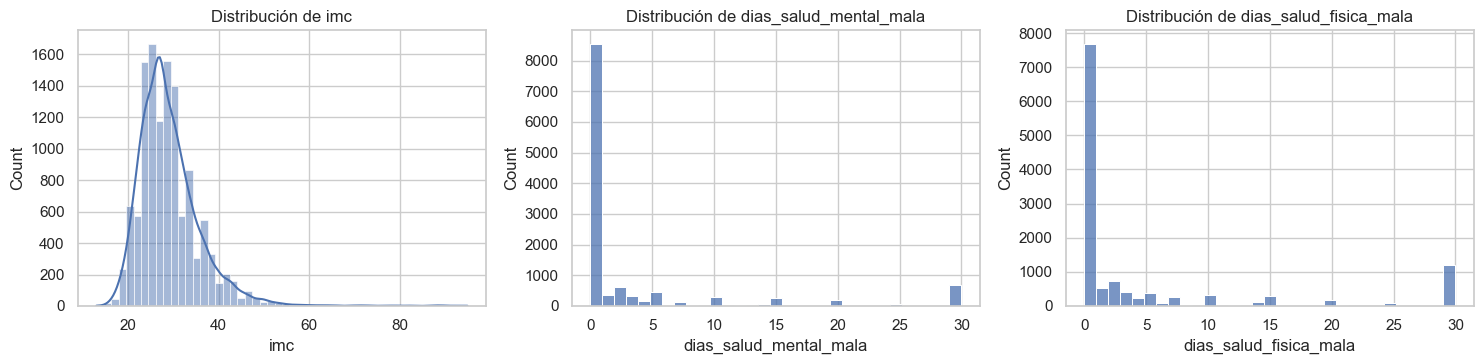

In [22]:
# Histogramas de las numéricas (31 barras en los días, una por cada valor de 0 a 30)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, NUMERICAS):
    sns.histplot(df[c], bins=31 if "dias" in c else 50, kde=(c == "imc"), ax=ax)
    ax.set_title(f"Distribución de {c}")
plt.tight_layout()
plt.show()

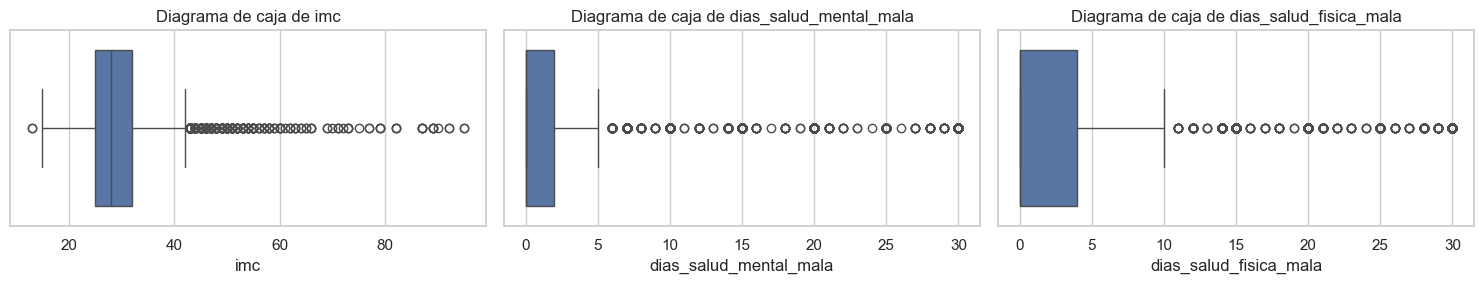

In [23]:
# Diagramas de caja de las numéricas
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, c in zip(axes, NUMERICAS):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(f"Diagrama de caja de {c}")
plt.tight_layout()
plt.show()

- El **IMC** tiene forma de campana con una cola larga a la derecha.
- Los **días de mala salud** tienen dos picos, en 0 y en 30, y los valores intermedios se agrupan en números redondos (5, 10, 15...), porque la gente responde de memoria. En el boxplot casi todo lo que no es 0 sale como atípico, así que el criterio del IQR no sirve para estas variables.

### 3.2 Variables binarias

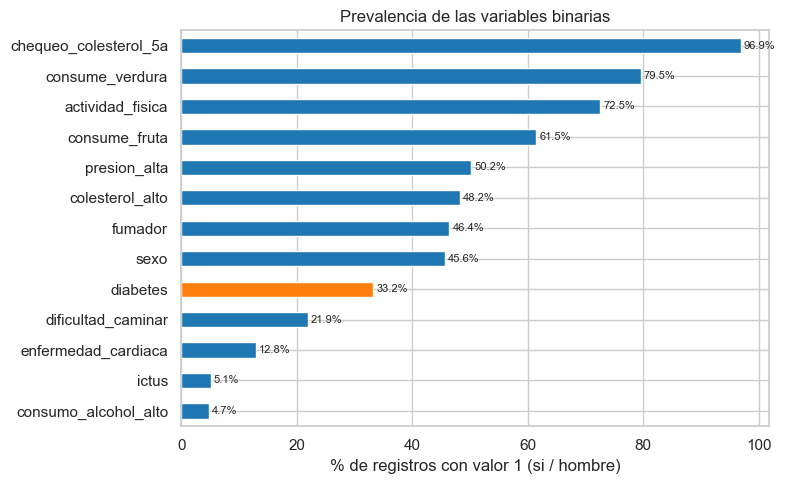

In [24]:
# Gráfico de barras con la prevalencia de cada binaria (la diabetes en naranja)
prev = (df[BINARIAS + [OBJ_CLF]].astype(float).mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
prev.plot.barh(ax=ax, color=["tab:orange" if c == OBJ_CLF else "tab:blue" for c in prev.index])
ax.set_xlabel("% de registros con valor 1 (si / hombre)")
ax.set_title("Prevalencia de las variables binarias")
# Escribo el porcentaje al lado de cada barra
for i, v in enumerate(prev):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Algunas binarias están muy desbalanceadas (`chequeo_colesterol_5a`, `consumo_alcohol_alto`, `ictus`). Aun así pueden estar muy ligadas a los objetivos cuando aparecen, como se ve en el apartado 4.

### 3.3 Variables ordinales

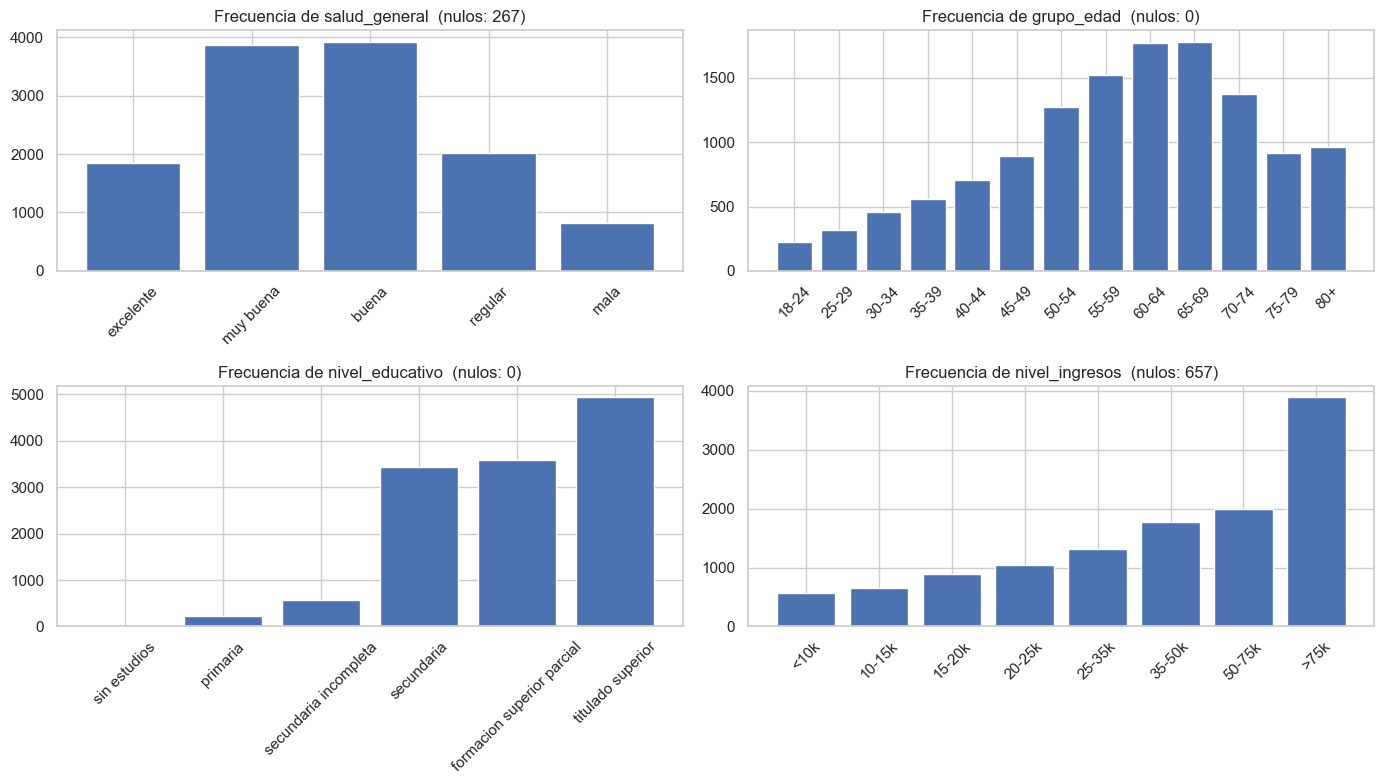

In [25]:
# Un gráfico de barras por ordinal, con las categorías en su orden y el nº de nulos en el título
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.ravel(), ORD):
    cnt = df[c].value_counts().sort_index()
    ax.bar([ORDINALES[c][int(i) - 1] for i in cnt.index], cnt.values)
    ax.set_title(f"Frecuencia de {c}  (nulos: {df[c].isna().sum()})")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

- **Edad**: la muestra se concentra entre 50 y 74 años, seguramente por haber sobremuestreado a los diabéticos.
- **Nivel educativo**: casi todo es secundaria o superior; `sin estudios` tiene solo 7 casos.
- **Ingresos**: la categoría más frecuente es `>75k`.
- **Salud general**: la mayoría se valora como buena o muy buena.

## 4. Relaciones entre variables

Uso dos herramientas:

- **Tasas por grupo**: el % de diabéticos o la media de días en cada categoría. Es lo más fácil de explicar.
- **Correlación de Spearman**: como la de Pearson, pero calculada sobre el orden de los valores, así que sirve para variables binarias y ordinales y no le afectan los atípicos.

### 4.1 Relación con `diabetes`

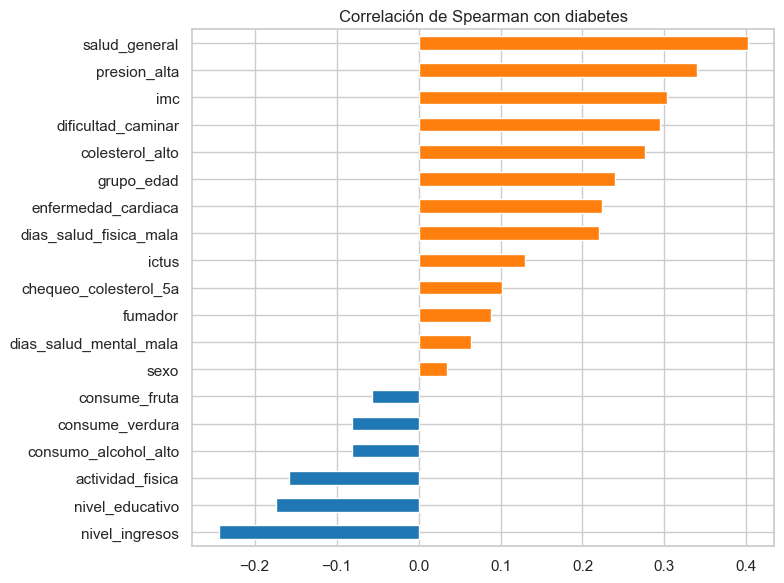

,spearman
salud_general,0.401
presion_alta,0.340
imc,0.303
dificultad_caminar,0.294
colesterol_alto,0.276
nivel_ingresos,-0.244
grupo_edad,0.239
enfermedad_cardiaca,0.224
dias_salud_fisica_mala,0.220
nivel_educativo,-0.174


In [26]:
# Correlación de Spearman de cada variable con la diabetes (que está codificada como 0/1)
corr_clf = (df.astype(float).corr(method="spearman")[OBJ_CLF]
            .drop(OBJ_CLF).sort_values(key=abs, ascending=False))

# En naranja las relaciones positivas (más diabetes) y en azul las negativas
orden = corr_clf.sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
orden.plot.barh(ax=ax, color=np.where(orden > 0, "tab:orange", "tab:blue"))
ax.set_title("Correlación de Spearman con diabetes")
plt.tight_layout()
plt.show()
corr_clf.round(3).to_frame("spearman")

In [27]:
# % de diabéticos según el valor de cada binaria, y la diferencia entre los dos grupos
tasa_bin = pd.DataFrame({c: df.groupby(c)[OBJ_CLF].mean() * 100 for c in BINARIAS}).T
tasa_bin.columns = ["% diabetes si=0", "% diabetes si=1"]
tasa_bin["diferencia"] = tasa_bin.iloc[:, 1] - tasa_bin.iloc[:, 0]
tasa_bin.astype(float).sort_values("diferencia", ascending=False).round(1)

,% diabetes si=0,% diabetes si=1,diferencia
dificultad_caminar,25.8,59.3,33.5
presion_alta,17.2,49.2,32.0
enfermedad_cardiaca,29.2,60.8,31.6
ictus,31.8,59.7,27.9
chequeo_colesterol_5a,6.3,34.1,27.8
colesterol_alto,20.7,46.7,26.0
fumador,29.3,37.6,8.3
sexo,31.7,35.0,3.3
consume_fruta,36.5,31.0,-5.5
consume_verdura,40.8,31.3,-9.5


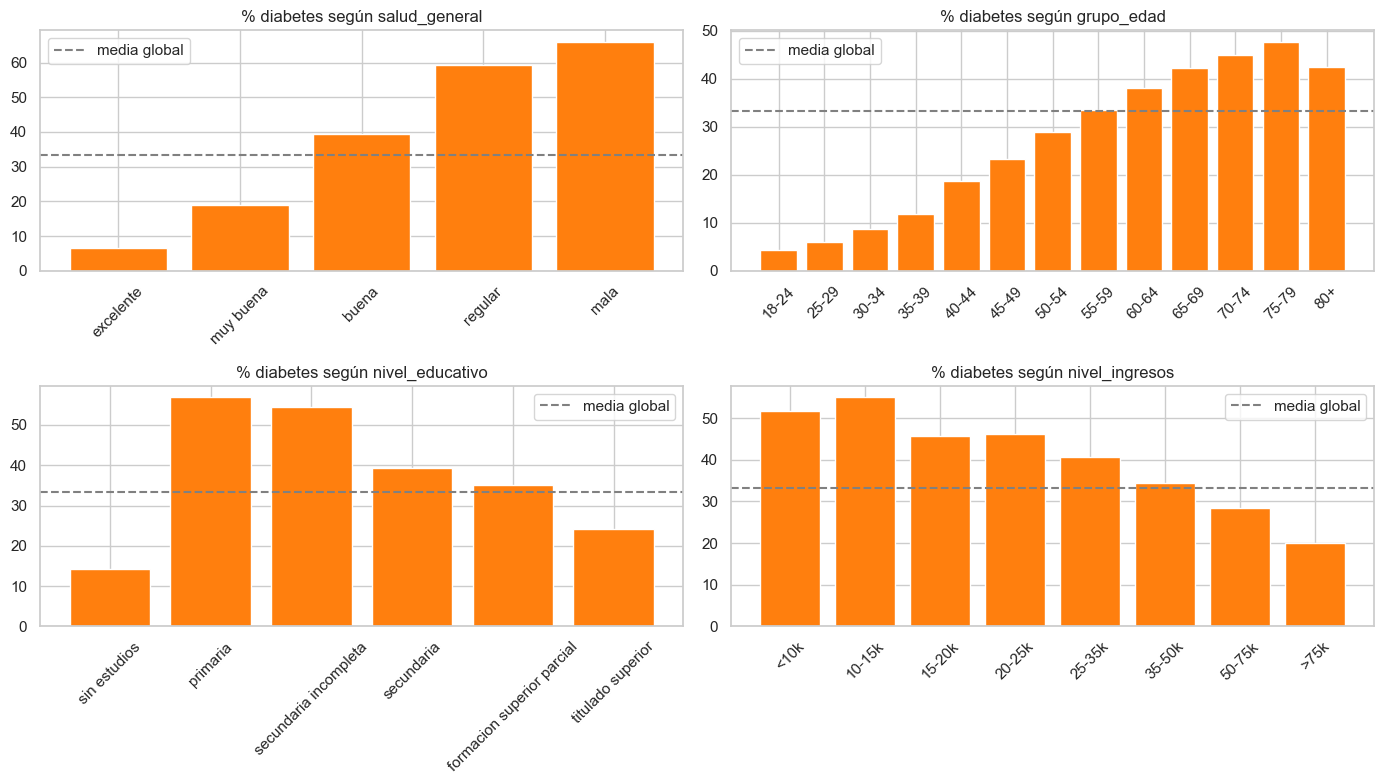

In [28]:
# % de diabéticos en cada categoría de las ordinales, con la media global como referencia
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
base = df[OBJ_CLF].mean() * 100
for ax, c in zip(axes.ravel(), ORD):
    t = df.groupby(c)[OBJ_CLF].mean() * 100
    ax.bar([ORDINALES[c][int(i) - 1] for i in t.index], t.values, color="tab:orange")
    ax.axhline(base, ls="--", c="gray", label="media global")
    ax.set_title(f"% diabetes según {c}")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

Las variables más relacionadas con la diabetes son:

- **Salud general**: la tasa de diabetes sube casi de forma lineal de `excelente` a `mala`.
- **Presión alta y colesterol alto**: los factores de riesgo metabólico clásicos.
- **Edad**: la tasa sube del 4 % (18-24) a casi el 48 % (75-79) y baja un poco en 80+.
- **Ingresos y nivel educativo**: a menos ingresos y estudios, más diabetes.
- **Dificultad para caminar y enfermedad cardíaca**.

En cambio, `sexo`, `consume_verdura` o `fumador` apenas aportan. Como las relaciones con las ordinales son monótonas, tiene sentido codificarlas como números enteros.

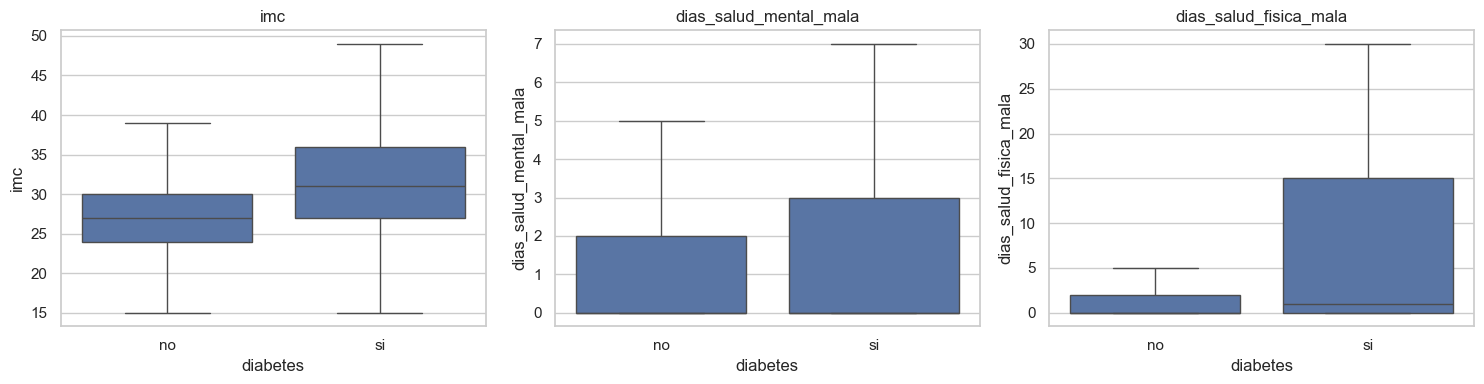

imc                       mediana no= 27.0  si= 31.0  | media no=27.76  si=31.88
dias_salud_mental_mala    mediana no=  0.0  si=  0.0  | media no= 2.84  si= 4.59
dias_salud_fisica_mala    mediana no=  0.0  si=  1.0  | media no= 3.47  si= 8.01


In [29]:
# Las numéricas frente a la diabetes: diagramas de caja sin los atípicos para que se vea la caja
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, NUMERICAS):
    sns.boxplot(x=df[OBJ_CLF].map({0: "no", 1: "si"}), y=df[c], ax=ax, showfliers=False)
    ax.set_title(c)
    ax.set_xlabel("diabetes")
plt.tight_layout()
plt.show()

# Medianas y medias de cada numérica en los dos grupos
for c in NUMERICAS:
    a, b = [g[c].dropna() for _, g in df.groupby(OBJ_CLF)]
    print(f"{c:<25} mediana no={a.median():5.1f}  si={b.median():5.1f}  | "
          f"media no={a.mean():5.2f}  si={b.mean():5.2f}")

In [30]:
# IMC agrupado por las categorías de la OMS, que es más fácil de explicar a un sanitario
cat_imc = pd.cut(df["imc"], [0, 18.5, 25, 30, 35, 40, 100],
                 labels=["bajo peso", "normal", "sobrepeso", "obesidad I", "obesidad II", "obesidad III"])
t = df.groupby(cat_imc, observed=True)[OBJ_CLF].agg(["mean", "size"])
t["mean"] = (t["mean"].astype(float) * 100).round(1)
t.columns = ["% diabetes", "n"]
t

,% diabetes,n
imc,,
bajo peso,14.5,145
normal,17.5,3675
sobrepeso,30.6,4426
obesidad I,44.3,2364
obesidad II,56.5,1026
obesidad III,61.9,717


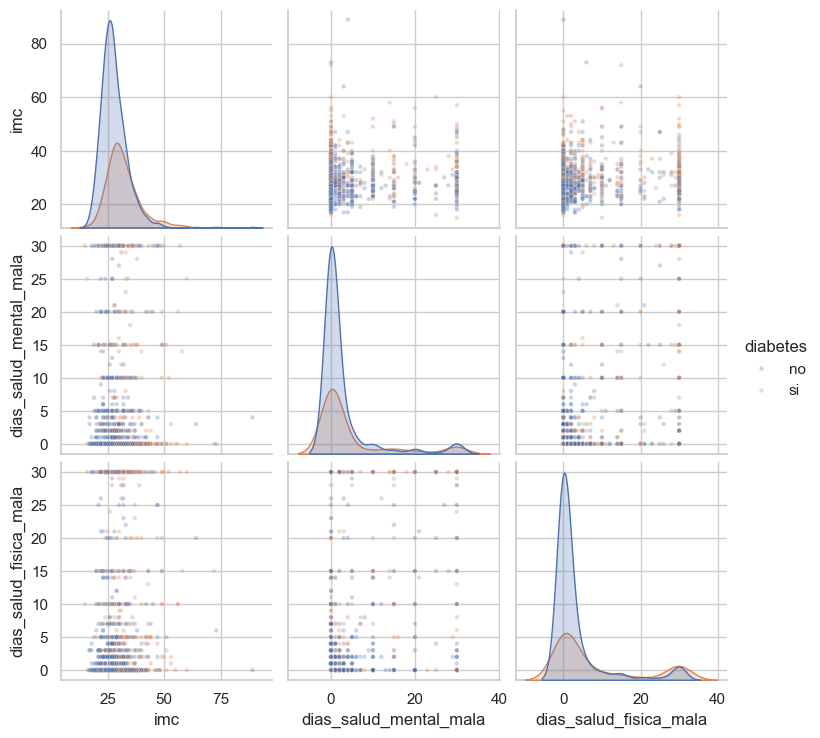

In [31]:
# Matriz de dispersión, con una muestra para que no tarde ni se sature el gráfico
muestra = df[NUMERICAS + [OBJ_CLF]].dropna().sample(1500, random_state=SEMILLA).astype(float)
muestra[OBJ_CLF] = muestra[OBJ_CLF].map({0: "no", 1: "si"})
sns.pairplot(muestra, hue=OBJ_CLF, plot_kws={"alpha": 0.3, "s": 10}, diag_kind="kde")
plt.show()

El **IMC** es mayor en diabéticos (mediana de 31 frente a 27), y por categorías de peso la tasa de diabetes sube del 17 % en peso normal al 62 % en obesidad III. Los días de mala salud también son mayores en diabéticos, aunque aquí son más una consecuencia de la diabetes que una causa. En la matriz de dispersión no se ve una separación clara entre los dos grupos usando solo estas tres variables.

### 4.2 Relación con `dias_salud_fisica_mala`

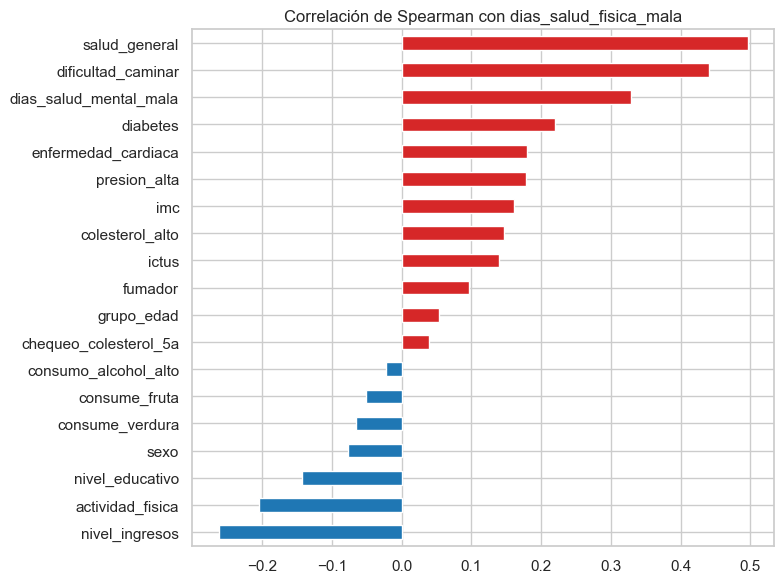

,spearman
salud_general,0.496
dificultad_caminar,0.440
dias_salud_mental_mala,0.329
nivel_ingresos,-0.262
diabetes,0.220
actividad_fisica,-0.204
enfermedad_cardiaca,0.180
presion_alta,0.178
imc,0.162
colesterol_alto,0.147


In [32]:
# Spearman de cada variable con los días de mala salud física
corr_reg = (df.astype(float).corr(method="spearman")[OBJ_REG]
            .drop(OBJ_REG).sort_values(key=abs, ascending=False))

# En rojo las correlaciones positivas y en azul las negativas
orden = corr_reg.sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
orden.plot.barh(ax=ax, color=np.where(orden > 0, "tab:red", "tab:blue"))
ax.set_title("Correlación de Spearman con dias_salud_fisica_mala")
plt.tight_layout()
plt.show()
corr_reg.round(3).to_frame("spearman")

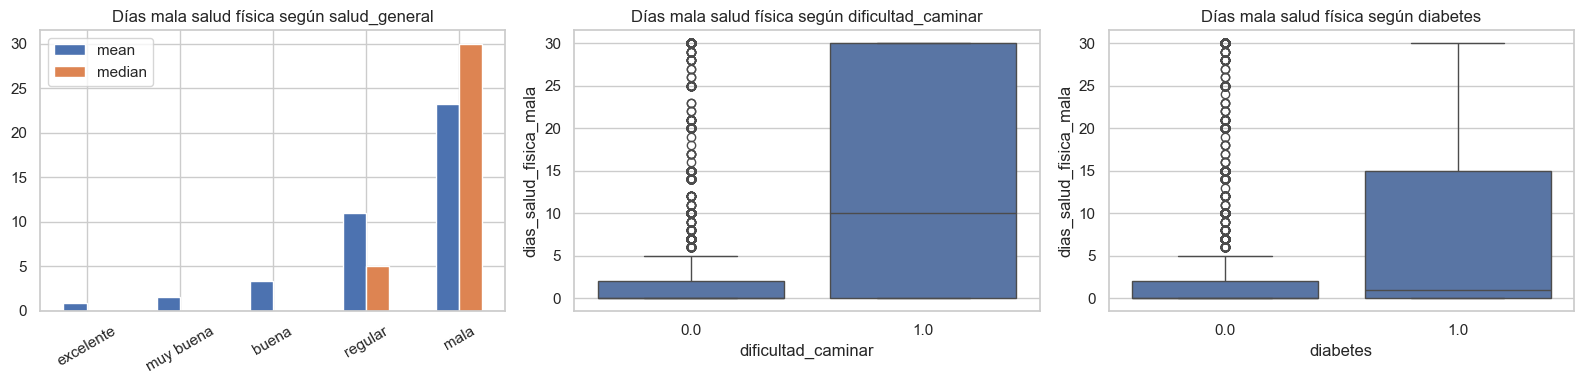

,pct_cero,pct_30,media
excelente,85.0,1.1,0.9
muy buena,74.7,1.7,1.6
buena,61.7,4.6,3.4
regular,29.2,20.1,11.0
mala,6.5,60.8,23.3


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Media y mediana de días según la salud general
g = df.groupby("salud_general")[OBJ_REG].agg(["mean", "median"])
g.index = [ORDEN_SALUD[int(i) - 1] for i in g.index]
g.plot.bar(ax=axes[0], rot=30)
axes[0].set_title("Días mala salud física según salud_general")

# Diagramas de caja según dificultad para caminar y diabetes
for ax, c in zip(axes[1:], ["dificultad_caminar", "diabetes"]):
    sns.boxplot(x=df[c].astype(float), y=df[OBJ_REG], ax=ax)
    ax.set_title(f"Días mala salud física según {c}")
plt.tight_layout()
plt.show()

# Proporción de ceros y de treintas en cada nivel de salud general
t = df.groupby("salud_general")[OBJ_REG].agg(pct_cero=lambda s: (s == 0).mean() * 100,
                                              pct_30=lambda s: (s == 30).mean() * 100,
                                              media="mean")
t.index = [ORDEN_SALUD[int(i) - 1] for i in t.index]
t.round(1)

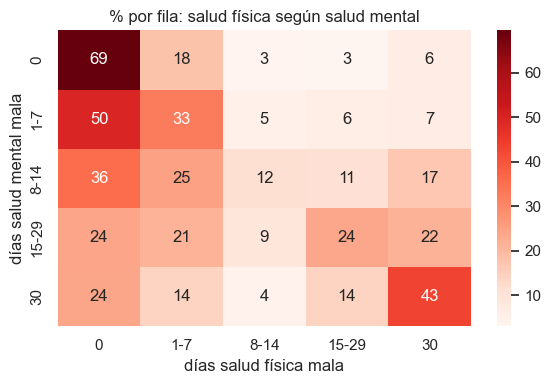

In [34]:
# Relación entre los dos conteos de días, agrupados por tramos
tramos = [-1, 0, 7, 14, 29, 30]
etiquetas = ["0", "1-7", "8-14", "15-29", "30"]
ct = pd.crosstab(pd.cut(df["dias_salud_mental_mala"], tramos, labels=etiquetas),
                 pd.cut(df[OBJ_REG], tramos, labels=etiquetas),
                 normalize="index") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Reds")
plt.xlabel("días salud física mala")
plt.ylabel("días salud mental mala")
plt.title("% por fila: salud física según salud mental")
plt.tight_layout()
plt.show()

La variable que más explica los días de mala salud física es **`salud_general`**: quien tiene salud `mala` declara unos 23 días de media, frente a menos de 1 con salud `excelente`, y los ceros pasan del 85 % al 6,5 %. Detrás van `dificultad_caminar` y `dias_salud_mental_mala`.

Ninguna correlación pasa de 0,5, así que el modelo de regresión tendrá un error considerable. Es lógico, porque los días de mala salud dependen de muchas cosas que la encuesta no recoge.

### 4.3 Matriz de correlación

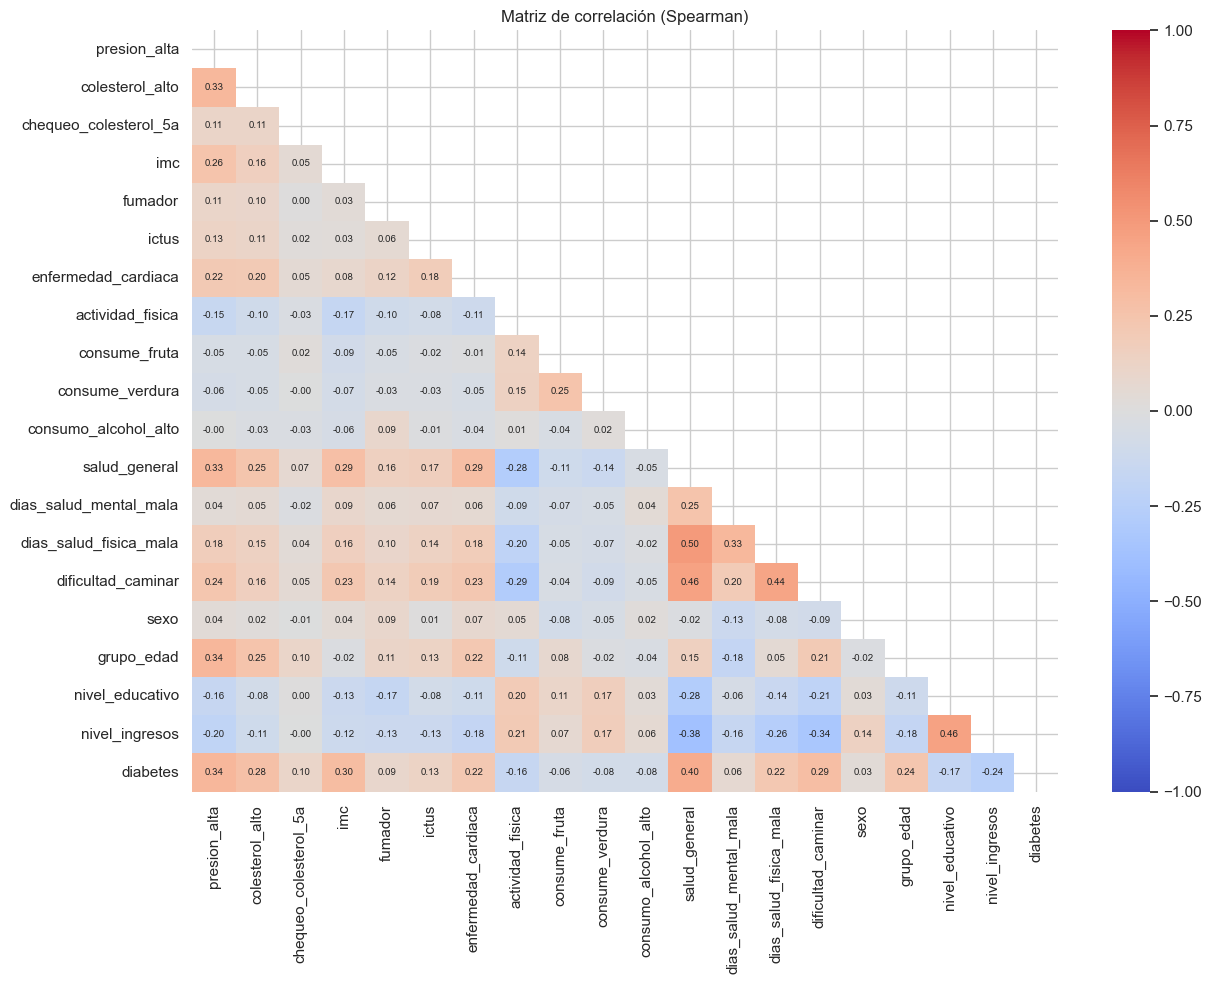

,level_0,level_1,rho
89,dias_salud_fisica_mala,salud_general,0.496
170,nivel_ingresos,nivel_educativo,0.458
102,dificultad_caminar,salud_general,0.456
104,dificultad_caminar,dias_salud_fisica_mala,0.440
182,diabetes,salud_general,0.401
164,nivel_ingresos,salud_general,-0.382
120,grupo_edad,presion_alta,0.340
171,diabetes,presion_alta,0.340
167,nivel_ingresos,dificultad_caminar,-0.336
0,colesterol_alto,presion_alta,0.330


In [35]:
# Matriz de correlación de Spearman entre todas las variables (con la mitad de arriba oculta porque es simétrica)
corr = df.astype(float).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title("Matriz de correlación (Spearman)")
plt.tight_layout()
plt.show()

# Las 10 parejas más correladas, para vigilar la multicolinealidad
pares = corr.where(~mask).stack().rename("rho").reset_index()
pares = pares.reindex(pares["rho"].abs().sort_values(ascending=False).index)
pares.head(10).round(3)

Ninguna pareja de variables pasa de 0,5, así que no hay multicolinealidad fuerte y no hace falta eliminar ni combinar variables. Se ven dos bloques: uno de **estado de salud** (salud general, días de mala salud, dificultad para caminar) y otro **socioeconómico** (ingresos y estudios).

Hay un grupo de variables con correlación por debajo de 0,1 con los dos objetivos (`sexo`, `fumador`, `consume_fruta`, `consume_verdura`, `consumo_alcohol_alto`). Serían las primeras candidatas a quitar si hiciera falta reducir variables.

### 4.4 Interacciones entre factores de riesgo

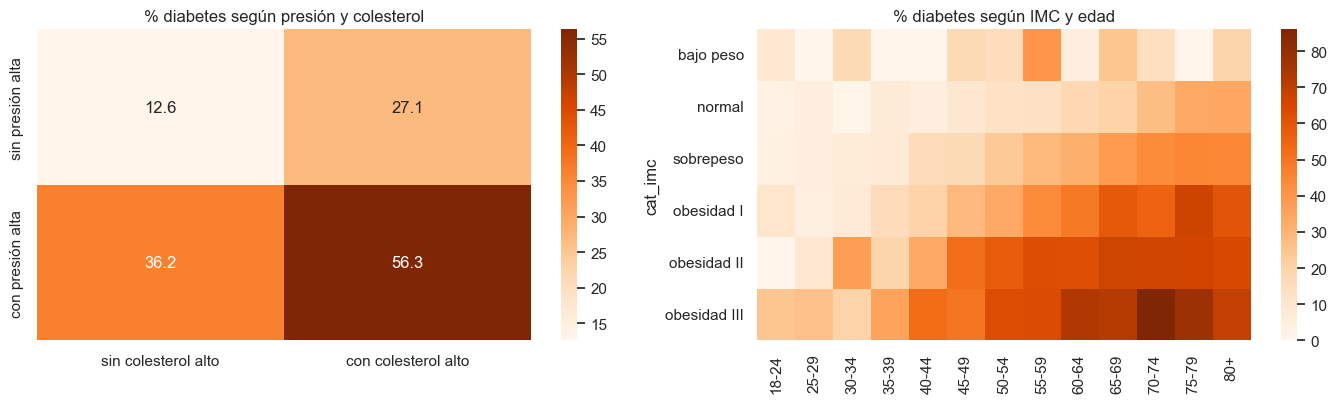

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# % de diabetes combinando presión alta y colesterol alto
piv = df.pivot_table(index="presion_alta", columns="colesterol_alto", values=OBJ_CLF,
                     aggfunc="mean").astype(float) * 100
piv.index = ["sin presión alta", "con presión alta"]
piv.columns = ["sin colesterol alto", "con colesterol alto"]
sns.heatmap(piv, annot=True, fmt=".1f", cmap="Oranges", ax=axes[0])
axes[0].set_title("% diabetes según presión y colesterol")

# % de diabetes combinando categoría de IMC y grupo de edad
piv2 = df.assign(cat_imc=cat_imc).pivot_table(index="cat_imc", columns="grupo_edad", values=OBJ_CLF,
                                              aggfunc="mean", observed=True).astype(float) * 100
piv2.columns = [ORDEN_EDAD[int(i) - 1] for i in piv2.columns]
sns.heatmap(piv2, cmap="Oranges", ax=axes[1])
axes[1].set_title("% diabetes según IMC y edad")
plt.tight_layout()
plt.show()

Los factores de riesgo se acumulan: con presión y colesterol altos a la vez la tasa de diabetes se dispara, y la combinación de obesidad y edad avanzada es la zona de más riesgo. Los modelos que captan interacciones, como los árboles, pueden sacar partido de esto.

## 5. Análisis de valores perdidos

In [37]:
# Nº y % de nulos por columna
nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})

,nulos,%
nivel_ingresos,657,5.15
imc,397,3.11
dias_salud_mental_mala,397,3.11
fumador,376,2.95
consume_fruta,376,2.95
actividad_fisica,376,2.95
dificultad_caminar,376,2.95
salud_general,267,2.09


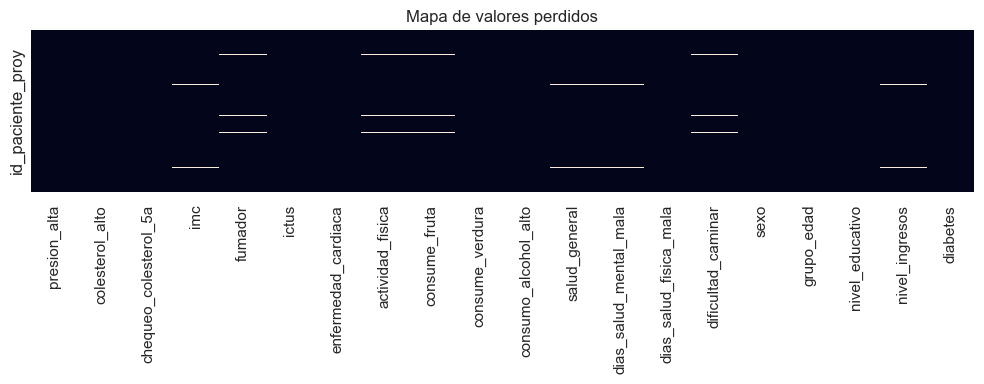

In [38]:
# Mapa de valores perdidos: cada línea blanca es una fila con ese dato ausente
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Mapa de valores perdidos")
plt.tight_layout()
plt.show()

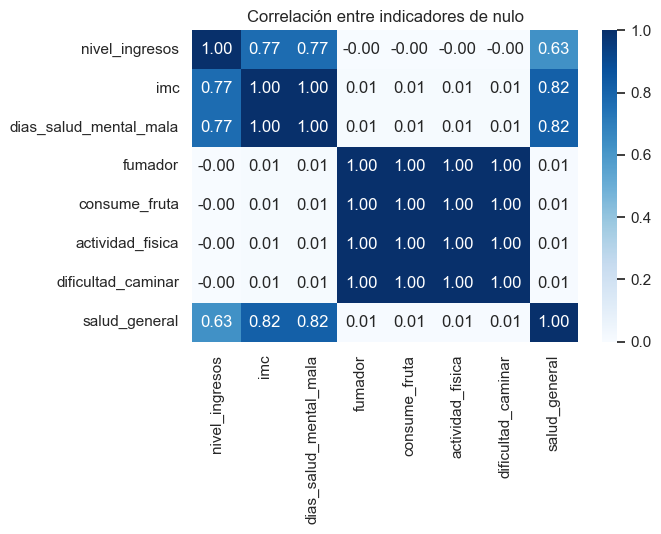

Nº de columnas con nulo por fila:
0    11735
1      257
3      125
4      615
5        3
7        5
8       10
Name: count, dtype: int64


In [39]:
# ¿Faltan juntas algunas columnas? Correlación entre los indicadores de nulo (1 = falta)
m = df[nulos.index].isnull().astype(int)
plt.figure(figsize=(7, 5.5))
sns.heatmap(m.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlación entre indicadores de nulo")
plt.tight_layout()
plt.show()

# Cuántas filas tienen 0, 1, 2... columnas con nulo
print("Nº de columnas con nulo por fila:")
print(m.sum(axis=1).value_counts().sort_index())

Los nulos van en **bloques**:

- `fumador`, `actividad_fisica`, `consume_fruta` y `dificultad_caminar` faltan siempre juntos (376 filas).
- `imc` y `dias_salud_mental_mala` también faltan juntos (397 filas).
- `salud_general` (267) y `nivel_ingresos` (657) van por libre.

Ninguna columna pasa del 5,2 %, así que no elimino columnas. Quitar las filas con nulos supondría perder unas 1.000, así que es mejor imputar. Antes miro si que falte el dato tiene relación con los objetivos.

In [40]:
# Para cada columna con nulos comparo los objetivos entre las filas donde falta y donde no
filas = []
for c in nulos.index:
    falta = df[c].isna()
    filas.append({
        "columna": c,
        "n_falta": int(falta.sum()),
        "%diabetes_si_falta": df.loc[falta, OBJ_CLF].mean() * 100,
        "%diabetes_no_falta": df.loc[~falta, OBJ_CLF].mean() * 100,
        "media_dias_fis_si_falta": df.loc[falta, OBJ_REG].mean(),
        "media_dias_fis_no_falta": df.loc[~falta, OBJ_REG].mean(),
    })
pd.DataFrame(filas).set_index("columna").astype(float).round(2)

,n_falta,%diabetes_si_falta,%diabetes_no_falta,media_dias_fis_si_falta,media_dias_fis_no_falta
columna,,,,,
nivel_ingresos,657.0,34.25,33.18,4.77,4.99
imc,397.0,36.78,33.13,4.84,4.98
dias_salud_mental_mala,397.0,36.78,33.13,4.84,4.98
fumador,376.0,36.97,33.13,5.78,4.96
consume_fruta,376.0,36.97,33.13,5.78,4.96
actividad_fisica,376.0,36.97,33.13,5.78,4.96
dificultad_caminar,376.0,36.97,33.13,5.78,4.96
salud_general,267.0,38.20,33.13,4.22,5.00


Que falte el dato apenas cambia los objetivos: en las filas con nulos hay entre un 34 % y un 38 % de diabéticos, frente al 33 % general, y la media de días cambia menos de un día. Los nulos parecen fallos de carga, no pacientes especiales.

**Tratamiento:**
- No eliminar filas ni columnas.
- Imputar con la **mediana** las numéricas (son asimétricas) y con la **moda** las binarias y ordinales. También se puede probar `KNNImputer` o `IterativeImputer`.
- Ajustar el imputador **solo con el train**, para no tener fuga de información.

## 6. Análisis de valores atípicos

In [41]:
def iqr_outliers(series):
    """Devuelve los valores fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR]."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]


# Nº de atípicos por el criterio IQR en cada numérica
for col in NUMERICAS:
    outliers = iqr_outliers(df[col].dropna())
    print(f"{col}: {len(outliers)} valores atípicos ({len(outliers) / df[col].notna().sum() * 100:.1f}%)")

imc: 516 valores atípicos (4.2%)
dias_salud_mental_mala: 1849 valores atípicos (15.0%)
dias_salud_fisica_mala: 2058 valores atípicos (16.1%)


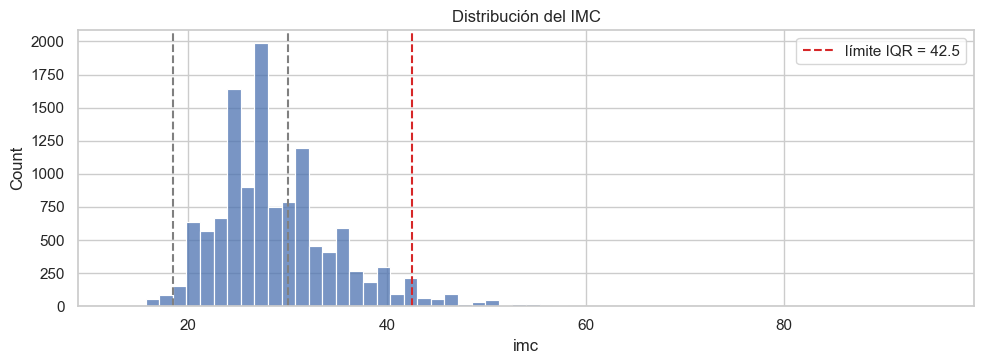

IMC: min=13.0, max=95.0
IMC > límite IQR: 514  |  IMC > 60: 46  |  IMC < 15: 2
¿IMC siempre entero? True


In [42]:
# Detalle del IMC: histograma con las líneas de 18,5 (bajo peso) y 30 (obesidad)
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(df["imc"], bins=60, ax=ax)
ax.axvline(18.5, ls="--", c="gray")
ax.axvline(30, ls="--", c="gray")
# Límite superior del IQR, para dibujarlo y para contar cuántos IMC lo pasan
q1, q3 = df["imc"].quantile([0.25, 0.75])
lim_sup_imc = q3 + 1.5 * (q3 - q1)
ax.axvline(lim_sup_imc, ls="--", c="tab:red", label=f"límite IQR = {lim_sup_imc:.1f}")
ax.set_title("Distribución del IMC")
ax.legend()
plt.tight_layout()
plt.show()

print(f"IMC: min={df['imc'].min()}, max={df['imc'].max()}")
print(f"IMC > límite IQR: {(df['imc'] > lim_sup_imc).sum()}  |  IMC > 60: {(df['imc'] > 60).sum()}  |  IMC < 15: {(df['imc'] < 15).sum()}")
print("¿IMC siempre entero?", (df["imc"].dropna() % 1 == 0).all())

- En los **días de mala salud** el IQR no sirve: como la mayoría son ceros, casi cualquier otro valor sale como atípico, pero todos están en el rango válido 0-30. No se tocan.
- En el **IMC** hay unos 500 valores por encima del límite del IQR y algunos llegan a 70-95. Son muy raros, pero posibles.

**Tratamiento:** eliminarlos sesgaría el modelo porque no son errores, e imputarlos sería inventarse datos. Así que los mantengo y uso **`RobustScaler`** (escala con la mediana y el IQR, y aguanta mejor los atípicos) en los modelos sensibles a la escala. Los modelos de árboles no lo necesitan.

In [43]:
# Registro los IMC por encima del límite del IQR como atípicos extremos
registra(
    columna="imc",
    tipo_incidencia="atipico_extremo",
    n_filas_afectadas=(df["imc"] > lim_sup_imc).sum(),
    accion="Se mantienen por ser valores posibles; RobustScaler en modelos sensibles a la escala.",
)

Registrada: imc / atipico_extremo (514 filas)


## 7. Análisis de las variables objetivo

### 7.1 `diabetes` (clasificación)

{np.int64(0): 8512, np.int64(1): 4238}
{np.int64(0): 66.8, np.int64(1): 33.2}


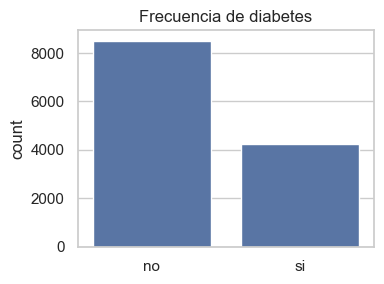

In [44]:
# Frecuencias absolutas y relativas de la diabetes
print(df[OBJ_CLF].value_counts().to_dict())
print((df[OBJ_CLF].value_counts(normalize=True) * 100).round(1).to_dict())

# Gráfico de barras
fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(x=df[OBJ_CLF].map({0: "no", 1: "si"}), ax=ax)
ax.set_title("Frecuencia de diabetes")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

Un **33 % son diabéticos**, por el remuestreo del enunciado. Esto implica:

- **Partición estratificada**, para mantener ese 33 % en train y en test.
- **No fiarse de la exactitud**: un modelo que dijera siempre "no diabético" ya acertaría un 67 %. Hay que mirar la matriz de confusión, la precisión, la sensibilidad y el F1.
- Como es una herramienta de **cribado**, lo más importante es que no se escapen diabéticos, así que la métrica principal es la **sensibilidad**.

Ojo: **esta no es la prevalencia real**. Las tasas de este EDA sirven para comparar grupos, pero no son cifras de la población, y las probabilidades del modelo tampoco lo serán.

### 7.2 `dias_salud_fisica_mala` (regresión)

Media: 4.98  |  Mediana: 0  |  Desv. típica: 9.43  |  Varianza: 88.9
% ceros: 60.3%  |  % 30: 9.3%  |  % entre 1 y 29: 30.3%


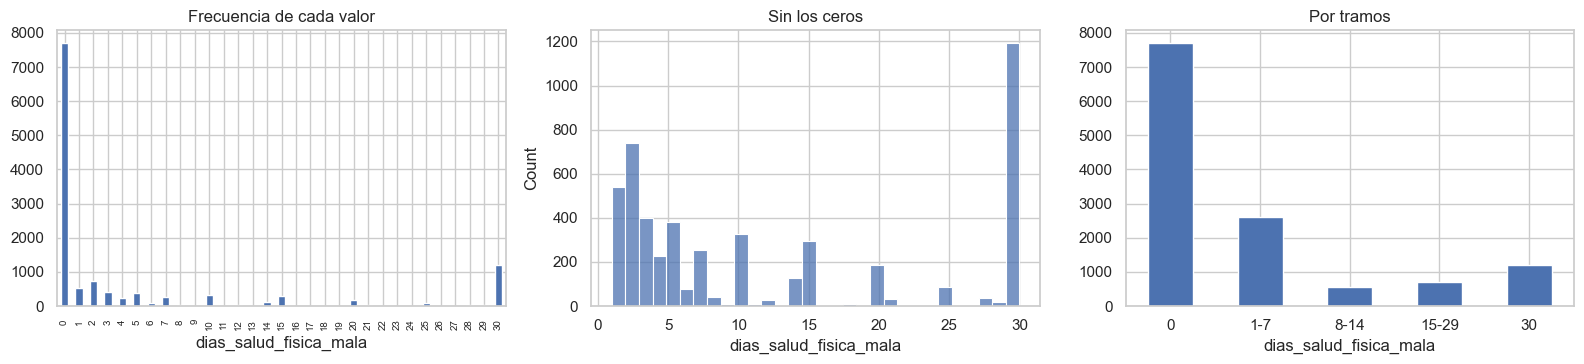

In [45]:
y = df[OBJ_REG]

# Estadísticos básicos y peso de cada pico
print(f"Media: {y.mean():.2f}  |  Mediana: {y.median():.0f}  |  Desv. típica: {y.std():.2f}  |  Varianza: {y.var():.1f}")
print(f"% ceros: {(y == 0).mean() * 100:.1f}%  |  % 30: {(y == 30).mean() * 100:.1f}%  |  "
      f"% entre 1 y 29: {((y > 0) & (y < 30)).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))

# Frecuencia de cada valor de 0 a 30
y.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Frecuencia de cada valor")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)

# Distribución quitando los ceros, para ver mejor el resto
sns.histplot(y[y > 0], bins=30, ax=axes[1])
axes[1].set_title("Sin los ceros")

# Por tramos
pd.cut(y, tramos, labels=etiquetas).value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Por tramos")
plt.tight_layout()
plt.show()

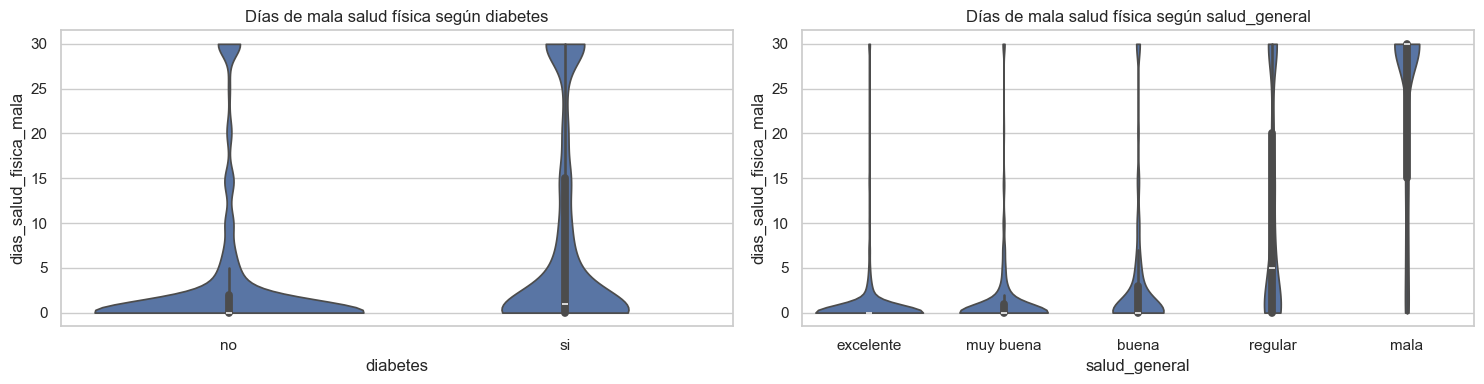

In [46]:
# Diagrama de violín de los días según la diabetes y según la salud general.
# El violín enseña la forma completa de la distribución, que el boxplot esconde
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.violinplot(x=df[OBJ_CLF].map({0: "no", 1: "si"}), y=y, cut=0, ax=axes[0])
axes[0].set_title("Días de mala salud física según diabetes")
axes[0].set_xlabel("diabetes")
sns.violinplot(x=df["salud_general"].map(lambda v: ORDEN_SALUD[int(v) - 1], na_action="ignore"), y=y,
               order=ORDEN_SALUD, cut=0, ax=axes[1])
axes[1].set_title("Días de mala salud física según salud_general")
axes[1].set_xlabel("salud_general")
plt.tight_layout()
plt.show()

Esta variable no es una continua normal:

- Un **60 % de ceros** y un **9 % de treintas**.
- Es **multimodal**: el violín muestra el pico en 0 y otro en 30, y en los pacientes con salud `mala` el pico principal pasa a 30. El boxplot esconde todo esto.
- Los valores intermedios se agrupan en números redondos.

Consecuencias para la regresión:

1. **Métrica**: el RMSE penaliza mucho los errores grandes, así que estará dominado por los 30. El **MAE** es más robusto y más fácil de explicar ("me equivoco de media en X días"). Conviene dar los dos.
2. **Modelo**: una distribución multimodal suele indicar que se mezclan subgrupos. Se puede probar un clasificador que decida si el paciente tiene 0 días o más, seguido de un regresor para los que tienen alguno. También conviene probar árboles y bosques de regresión.
3. **Predicciones**: recortarlas a [0, 30].
4. **Partición**: estratificar por tramos de días (0, 1-7, 8-14, 15-29, 30).

## 8. Exploración para la clusterización

Antes de hacer clusters quiero ver si los pacientes forman grupos. Para ello uso un **PCA**, solo como herramienta de visualización: resume las 18 variables en unos pocos ejes y así puedo dibujar a todos los pacientes en dos dimensiones. Antes estandarizo, porque el PCA es sensible a la escala.

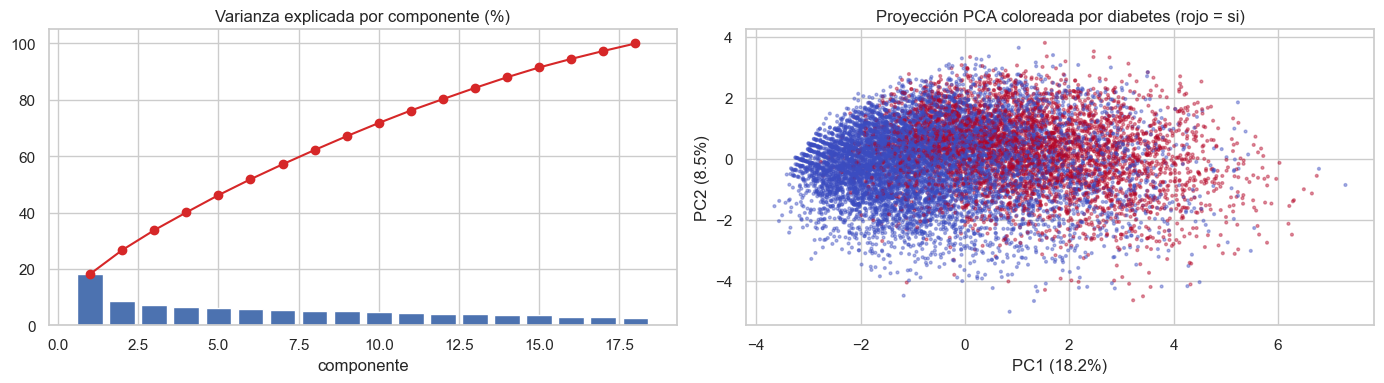

Varianza acumulada con 2 componentes: 26.6%  |  con 5: 46.2%


In [47]:
# Variables de la encuesta sin los objetivos, con los nulos rellenos con la mediana (solo para este análisis)
X_cl = df.drop(columns=[OBJ_CLF, OBJ_REG]).astype(float)
X_cl = X_cl.fillna(X_cl.median())

# Estandarizo (media 0, desviación 1), porque el PCA es sensible a la escala
Xs = StandardScaler().fit_transform(X_cl)

# PCA con todas las componentes para ver cuánta varianza explica cada una
pca = PCA(random_state=SEMILLA).fit(Xs)
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# Varianza explicada por componente (barras) y acumulada (línea roja)
axes[0].bar(range(1, len(var) + 1), var * 100)
axes[0].plot(range(1, len(var) + 1), np.cumsum(var) * 100, "o-", c="tab:red")
axes[0].set_title("Varianza explicada por componente (%)")
axes[0].set_xlabel("componente")

# Proyección de los pacientes sobre las dos primeras componentes, coloreada por diabetes
Z = pca.transform(Xs)[:, :2]
axes[1].scatter(Z[:, 0], Z[:, 1], c=df[OBJ_CLF].astype(int), cmap="coolwarm", s=4, alpha=0.4)
axes[1].set_xlabel(f"PC1 ({var[0] * 100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var[1] * 100:.1f}%)")
axes[1].set_title("Proyección PCA coloreada por diabetes (rojo = si)")
plt.tight_layout()
plt.show()

print(f"Varianza acumulada con 2 componentes: {var[:2].sum() * 100:.1f}%  |  con 5: {var[:5].sum() * 100:.1f}%")

In [48]:
# Cargas de cada variable en las tres primeras componentes, para poder interpretarlas
cargas = pd.DataFrame(pca.components_[:3].T, index=X_cl.columns, columns=["PC1", "PC2", "PC3"])
cargas.sort_values("PC1", key=abs, ascending=False).round(2)

,PC1,PC2,PC3
salud_general,0.41,-0.07,-0.07
dificultad_caminar,0.36,-0.05,-0.19
nivel_ingresos,-0.33,0.23,0.20
presion_alta,0.31,0.31,0.11
nivel_educativo,-0.28,0.21,0.00
actividad_fisica,-0.26,0.18,-0.06
enfermedad_cardiaca,0.25,0.24,0.06
colesterol_alto,0.24,0.34,0.12
grupo_edad,0.22,0.47,0.01
imc,0.21,-0.10,-0.02


Las dos primeras componentes explican solo un 27 % de la varianza, y en la proyección no hay grupos separados sino una nube continua. Es decir, **no hay clústeres naturales**, así que los perfiles serán una forma útil de dividir a la población.

- La **PC1** es un eje de **mala salud** (salud general, dificultad para caminar, presión alta, menos ingresos).
- La **PC2** recoge la **edad y el riesgo metabólico** junto con hábitos saludables y buena salud mental.

Para el clustering:

- Usar **pocas variables con sentido clínico** (edad, IMC, presión, colesterol, salud general, actividad física, dificultad para caminar), para que los grupos se puedan explicar.
- **Escalar** las variables, porque k-medias se basa en distancias.
- Dejar fuera `diabetes` y `dias_salud_fisica_mala` y usarlas después para **describir** cada grupo.

## 9. Registro de incidencias

In [49]:
# Paso la lista de incidencias a un dataframe para verla en tabla
registro = pd.DataFrame(INCIDENCIAS)
print(f"{len(registro)} incidencias registradas")
registro

22 incidencias registradas


,columna,tipo_incidencia,n_filas_afectadas,accion
0,dni,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
1,nombre,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
2,apellidos,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
3,direccion,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
4,telefono,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
5,email,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
6,num_historia_clinica,dato_personal,12750,Columna eliminada: cadena aleatoria sin valor ...
7,id_paciente_proy,columna_sin_valor_predictivo,12750,"Usado como índice, fuera de las variables de e..."
8,usuario_alta_datos,columna_sin_valor_predictivo,12750,Columna eliminada: columna de gestión interna ...
9,fumador,categoria_inconsistente,3200,Unificadas las variantes si/SI/True/1.0 y no/N...


In [50]:
# Resumen por tipo de incidencia
registro.groupby("tipo_incidencia")["n_filas_afectadas"].agg(["count", "sum"]).rename(
    columns={"count": "n_columnas", "sum": "filas_afectadas_total"})

,n_columnas,filas_afectadas_total
tipo_incidencia,,
atipico_extremo,1,514
categoria_inconsistente,4,12800
columna_sin_valor_predictivo,2,25500
dato_personal,7,89250
valor_ausente,8,3222


## 10. Exportación

Guardo el registro de incidencias y el dataset limpio, sin imputar ni escalar, porque eso se hace en el preprocesamiento de cada línea.

In [51]:
# Compruebo que el registro tiene el formato correcto antes de exportar
assert len(registro), "No hay ninguna incidencia registrada"
assert list(registro.columns) == ["columna", "tipo_incidencia", "n_filas_afectadas", "accion"], \
    "Las columnas del registro no son las esperadas"
assert registro["tipo_incidencia"].isin(CATALOGO).all(), "Hay etiquetas fuera del catálogo"

# Y que el dataset limpio no ha perdido filas ni tiene binarias con más de dos valores
assert len(df) == len(crudo), "Se han perdido filas por el camino"
assert (df[COLS_BIN + ["sexo"]].nunique() == 2).all(), "Hay alguna binaria con más de dos valores"

# Exporto los dos archivos
registro.to_csv("incidencias.csv", index=False, encoding="utf-8")
df.to_csv("proy_diabetes_limpio.csv", encoding="utf-8")

print(f"incidencias.csv           {len(registro)} incidencias")
print(f"proy_diabetes_limpio.csv  {df.shape[0]} filas x {df.shape[1]} columnas")

incidencias.csv           22 incidencias
proy_diabetes_limpio.csv  12750 filas x 20 columnas


## 11. Conclusiones

**Problemas encontrados, de más a menos grave:**

1. **Binarias escritas de cuatro formas** (3.200 filas, un 25 %). Sin corregir, los modelos tratarían `si` y `SI` como cosas distintas.
2. **Columnas personales y de gestión**: no aportan nada y solo añaden riesgo de sobreajuste y de protección de datos.
3. **Nulos y atípicos del IMC**: afectan a pocas filas, no se relacionan con los objetivos y se resuelven con imputación y `RobustScaler`.

No hay duplicados, valores centinela, filas desplazadas ni fuga de información.

| Problema | Decisión |
|---|---|
| Datos personales y `usuario_alta_datos` | Eliminar |
| `id_paciente_proy` | Usar como índice |
| Binarias con 4 codificaciones | Pasar a 0/1 |
| Nulos (≤ 5,2 % por columna) | Imputar con mediana o moda, ajustando con el train |
| IMC extremo (hasta 95) | Mantener y usar `RobustScaler` |
| `sin estudios` (7 casos) | Agruparla con `primaria` si se usa one-hot |
| 140 perfiles repetidos | Mantener |

**Líneas de trabajo:**

- **Clasificación**: 33 % de diabéticos, partición estratificada y sensibilidad como métrica principal. Las variables más útiles son salud general, presión alta, IMC, edad, colesterol, dificultad para caminar, enfermedad cardíaca e ingresos.
- **Regresión**: 60 % de ceros y pico en 30, así que conviene separar subgrupos, probar árboles, dar MAE y RMSE y recortar a [0, 30]. Las variables clave son salud general, dificultad para caminar y días de mala salud mental.
- **Clusterización**: sin grupos naturales; pocas variables clínicas, escaladas y fáciles de interpretar.

**Limitaciones:** por el remuestreo, las tasas del EDA no son las de la población real. Además, los días de mala salud son autodeclarados y redondeados, así que tienen un ruido que ningún modelo puede quitar.

En conclusión, el dataset es manejable una vez corregidas las codificaciones, y los resultados tienen sentido clínico. Lo importante para el siguiente paso es que la imputación y el escalado se ajusten solo con el train, porque si no las métricas saldrían más optimistas de lo que son.